# 1. Batch Gradient Descent

In [13]:
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt

In [14]:
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Input
from tensorflow.keras.utils import to_categorical

In [15]:
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Normalize data
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

In [16]:
# One-hot encoding
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

In [17]:
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

In [18]:
optimizer = tf.keras.optimizers.SGD(
    learning_rate=0.01
)

In [19]:
model.compile(
    optimizer=optimizer,
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [21]:
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=len(X_train),
    validation_split=0.2,
    verbose=1
)

Epoch 1/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 707ms/step - accuracy: 0.2901 - loss: 2.1681 - val_accuracy: 0.3094 - val_loss: 2.1532
Epoch 2/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 672ms/step - accuracy: 0.3057 - loss: 2.1567 - val_accuracy: 0.3243 - val_loss: 2.1421
Epoch 3/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 603ms/step - accuracy: 0.3199 - loss: 2.1457 - val_accuracy: 0.3353 - val_loss: 2.1313
Epoch 4/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 646ms/step - accuracy: 0.3333 - loss: 2.1349 - val_accuracy: 0.3466 - val_loss: 2.1207
Epoch 5/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.3456 - loss: 2.1245 - val_accuracy: 0.3572 - val_loss: 2.1104
Epoch 6/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.3556 - loss: 2.1142 - val_accuracy: 0.3652 - val_loss: 2.1002
Epoch 7/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 725ms/step - accuracy: 0.3649 - loss: 2.1041 - val_accuracy: 0.3728 - val_loss: 2.0902
Epoch 8/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.3721 - loss: 2.0942 - val_accuracy: 0.3790 - val_loss: 2.0803
E

In [22]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 1.9755926132202148
Test Accuracy: 0.41260001063346863


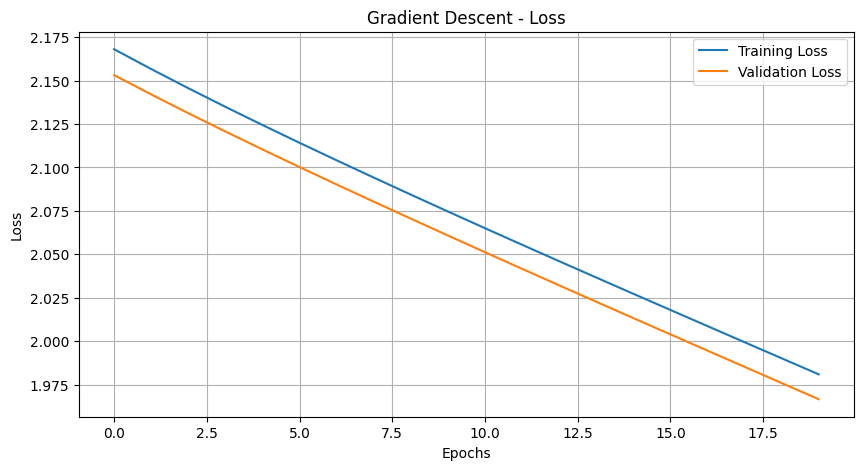

In [23]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Gradient Descent - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

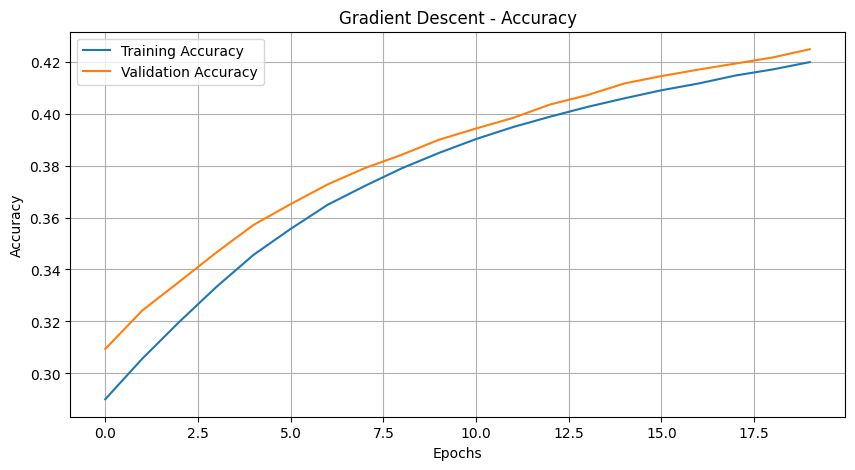

In [24]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Gradient Descent - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

# 2. Mini Batch Descent

In [25]:
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])


In [26]:
optimizer = tf.keras.optimizers.SGD(
    learning_rate=0.01
)

model.compile(
    optimizer=optimizer,
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [28]:
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=128,
    validation_split=0.2,
    verbose=1
)

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8476 - loss: 0.4389 - val_accuracy: 0.8395 - val_loss: 0.4510
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8501 - loss: 0.4317 - val_accuracy: 0.8463 - val_loss: 0.4371
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8520 - loss: 0.4253 - val_accuracy: 0.8469 - val_loss: 0.4355
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8532 - loss: 0.4197 - val_accuracy: 0.8508 - val_loss: 0.4303
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8554 - loss: 0.4139 - val_accuracy: 0.8513 - val_loss: 0.4232
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8567 - loss: 0.4087 - val_accuracy: 0.8524 - val_loss: 0.4216
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8595 - loss: 0.4044 - val_accuracy: 0.8542 - val_loss: 0.4179
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8604 - loss: 0.4000 - val_accuracy: 0.

In [29]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 0.4139179587364197
Test Accuracy: 0.8517000079154968


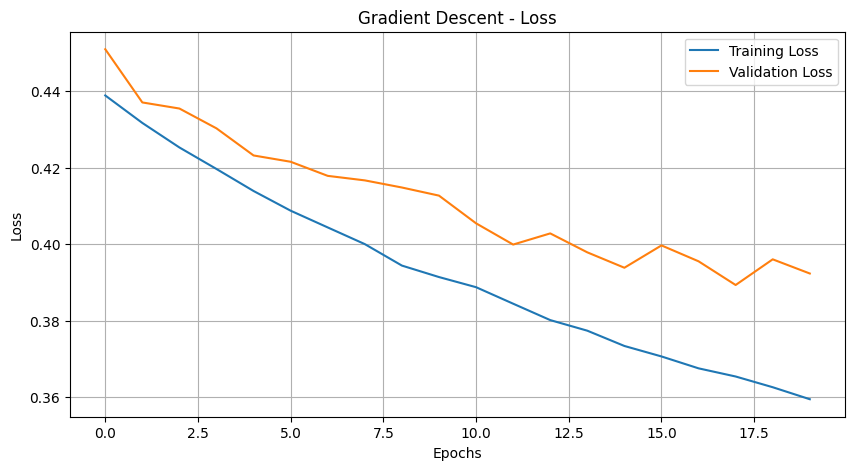

In [30]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Gradient Descent - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

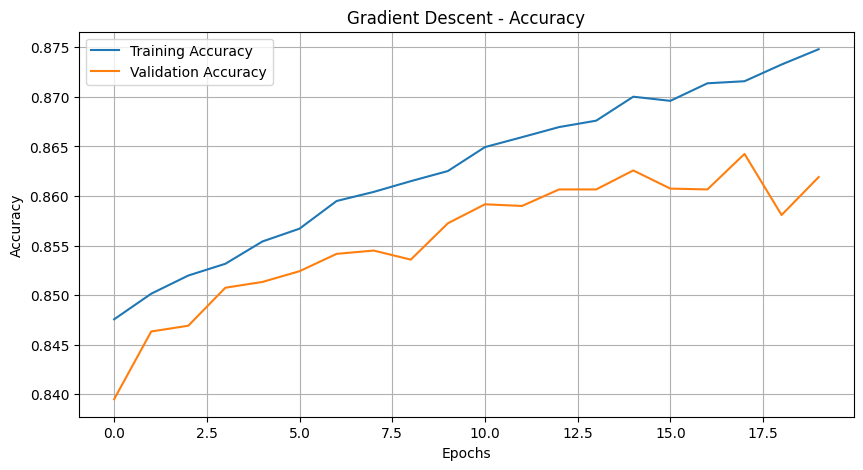

In [31]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Gradient Descent - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

# 3. Stochastic Gradient Descent

In [32]:
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

In [33]:
optimizer = tf.keras.optimizers.SGD(
    learning_rate=0.01
)

model.compile(
    optimizer=optimizer,
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [36]:
history = model.fit(
    X_train,
    y_train,
    epochs=2,
    batch_size=1,
    validation_split=0.2,
    verbose=1
)

Epoch 1/2
48000/48000 ━━━━━━━━━━━━━━━━━━━━ 132s 3ms/step - accuracy: 0.8346 - loss: 0.4507 - val_accuracy: 0.8449 - val_loss: 0.4313
Epoch 2/2
48000/48000 ━━━━━━━━━━━━━━━━━━━━ 130s 3ms/step - accuracy: 0.8571 - loss: 0.3887 - val_accuracy: 0.8580 - val_loss: 0.3872


In [37]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 0.41113853454589844
Test Accuracy: 0.8518999814987183


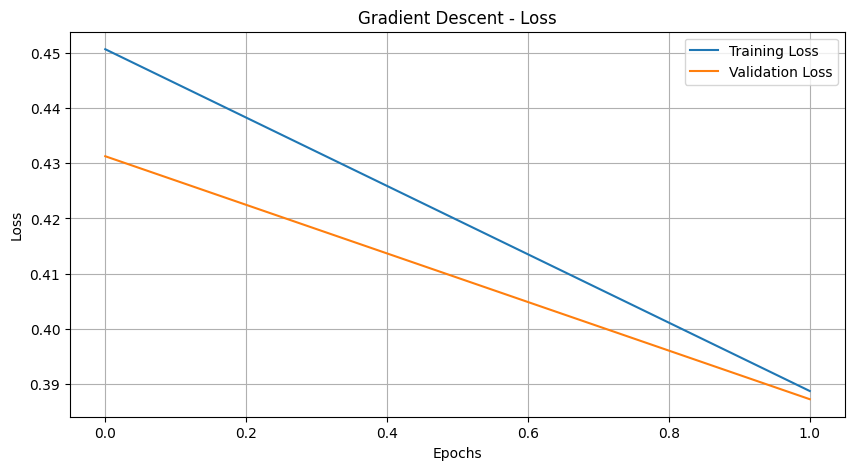

In [38]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Gradient Descent - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

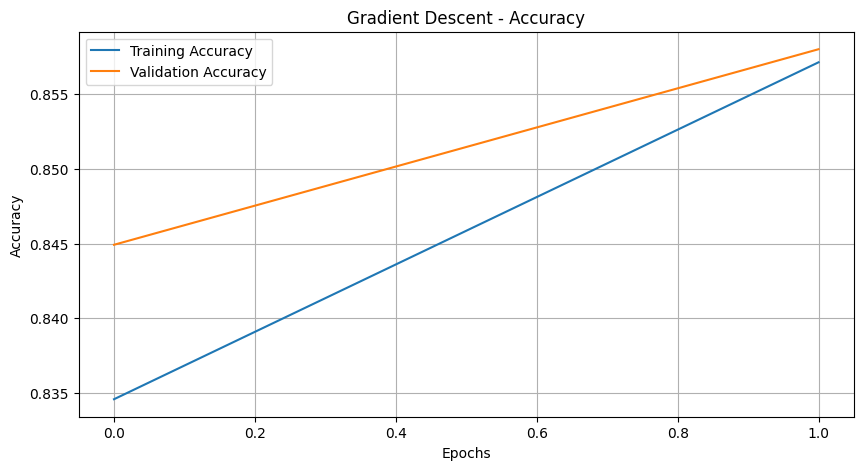

In [39]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Gradient Descent - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()